In [15]:
import torch
import numpy as np
import random

torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open("rt-polarity.pos", "r", encoding="latin-1") as f:
    pos_reviews = f.read().splitlines()

with open("rt-polarity.neg", "r", encoding="latin-1") as f:
    neg_reviews = f.read().splitlines()

reviews = pos_reviews + neg_reviews
labels = [1] * len(pos_reviews) + [0] * len(neg_reviews)

In [16]:
from collections import Counter

tokenized_reviews = [review.lower().split() for review in reviews]

word_counts = Counter()
for review in tokenized_reviews:
    word_counts.update(review)

# special tokens
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_IDX = 0
UNK_IDX = 1

vocabulary = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}

for word, count in word_counts.items():
    if count >= 1:
        vocabulary[word] = len(vocabulary)

print(len(vocabulary))

21426


In [17]:
# Convert to integers and pad sequences
MAX_LEN = 50

encoded_reviews = []
for review in reviews:
    encoded_review = [vocabulary.get(word, UNK_IDX) for word in review.lower().split()]
    if len(encoded_review) < MAX_LEN:
        encoded_review += [PAD_IDX] * (MAX_LEN - len(encoded_review))
    else:
        encoded_review = encoded_review[:MAX_LEN]
    encoded_reviews.append(encoded_review)

encoded_reviews = np.array(encoded_reviews)
labels = np.array(labels)

print(f"Encoded reviews shape: {encoded_reviews.shape}")

Encoded reviews shape: (10662, 50)


In [18]:
# Shuffle and split the dataset into training and testing sets

indices = np.arange(len(encoded_reviews))
np.random.shuffle(indices)

encoded_reviews = encoded_reviews[indices]
labels = labels[indices]

X_train, y_train = encoded_reviews[:8500], labels[:8500]
X_val, y_val = encoded_reviews[8500:9600], labels[8500:9600]
X_test, y_test = encoded_reviews[9600:], labels[9600:]

print(f"Training set size: {len(X_train)}")
print(f"Validation set size: {len(X_val)}")
print(f"Test set size: {len(X_test)}")

Training set size: 8500
Validation set size: 1100
Test set size: 1062


In [19]:
from torch.utils.data import DataLoader, Dataset

class MovieReviewDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64

train_loader = DataLoader(MovieReviewDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(MovieReviewDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(MovieReviewDataset(X_test, y_test), batch_size=BATCH_SIZE)

# Model A: Simple RNN Classifier

In [20]:
import torch.nn as nn

EMBEDDING_DIM = 128
HIDDEN_DIM = 128
vocab_size = len(vocabulary)

class SimpleRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(SimpleRNN, self).__init__()

        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=PAD_IDX)
        self.rnn = nn.RNN(input_size=embedding_dim, hidden_size=HIDDEN_DIM, batch_first=True)
        self.fc = nn.Linear(in_features=HIDDEN_DIM, out_features=1)

    def forward(self, x):
        embedded = self.embedding(x)
        out, hidden = self.rnn(embedded)
        final_hidden_state = hidden.squeeze(0)

        predictions = self.fc(final_hidden_state)

        return predictions.squeeze(1)

# Model B: LSTM classifier

In [21]:
class LSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(LSTM, self).__init__()

        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, batch_first=True)

        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(in_features=hidden_dim, out_features=1)

    def forward(self, x):
        embedded = self.embedding(x)
        out, (hidden, cell) = self.lstm(embedded)
        
        pooled_out = torch.mean(out, dim=1)
        
        predictions = self.fc(self.dropout(pooled_out))
        return predictions.squeeze(1)

In [22]:
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

def train_model(model, train_loader, val_loader, epochs=10, lr=0.001):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    model = model.to(device)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()
        epoch_train_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        model.eval()
        epoch_val_loss = 0
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)

                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                epoch_val_loss += loss.item()

                # Convert raw logits to 0 or 1 using sigmoid + round
                preds = torch.round(torch.sigmoid(predictions)).cpu().numpy()
                val_preds.extend(preds)
                val_targets.extend(y_batch.cpu().numpy())

        avg_train_loss = epoch_train_loss / len(train_loader)
        avg_val_loss = epoch_val_loss / len(val_loader)
        val_acc = accuracy_score(val_targets, val_preds)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch + 1:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), "best_model.pth")
    return model, history


In [23]:
print("Simple RNN")
rnn_model = SimpleRNN(vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM)
print(rnn_model)

Simple RNN
SimpleRNN(
  (embedding): Embedding(21426, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [24]:
print("LSTM")
lstm_model = LSTM(vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM)
print(lstm_model)

LSTM
LSTM(
  (embedding): Embedding(21426, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [25]:
print("Training Simple RNN")
rnn_model = SimpleRNN(vocab_size, EMBEDDING_DIM, HIDDEN_DIM)
rnn_model, rnn_hist = train_model(rnn_model, train_loader, val_loader, epochs=25)

Training Simple RNN
Epoch 01 | Train Loss: 0.6939 | Val Loss: 0.6971 | Val Acc: 0.4900
Epoch 02 | Train Loss: 0.6926 | Val Loss: 0.6950 | Val Acc: 0.4682
Epoch 03 | Train Loss: 0.6920 | Val Loss: 0.6960 | Val Acc: 0.4609
Epoch 04 | Train Loss: 0.6911 | Val Loss: 0.6961 | Val Acc: 0.4764
Epoch 05 | Train Loss: 0.6922 | Val Loss: 0.6941 | Val Acc: 0.5318
Epoch 06 | Train Loss: 0.6914 | Val Loss: 0.6946 | Val Acc: 0.4691
Epoch 07 | Train Loss: 0.6912 | Val Loss: 0.6958 | Val Acc: 0.4664
Epoch 08 | Train Loss: 0.6903 | Val Loss: 0.6935 | Val Acc: 0.5136
Epoch 09 | Train Loss: 0.6911 | Val Loss: 0.6960 | Val Acc: 0.4664
Epoch 10 | Train Loss: 0.6914 | Val Loss: 0.6934 | Val Acc: 0.4691
Epoch 11 | Train Loss: 0.6919 | Val Loss: 0.6942 | Val Acc: 0.4618
Epoch 12 | Train Loss: 0.6911 | Val Loss: 0.6952 | Val Acc: 0.4655
Epoch 13 | Train Loss: 0.6911 | Val Loss: 0.6942 | Val Acc: 0.5309
Epoch 14 | Train Loss: 0.6905 | Val Loss: 0.6934 | Val Acc: 0.5309
Epoch 15 | Train Loss: 0.6900 | Val Loss: 

In [26]:
print("Training LSTM")
lstm_model = LSTM(vocab_size, EMBEDDING_DIM, HIDDEN_DIM)
lstm_model, lstm_hist = train_model(lstm_model, train_loader, val_loader, epochs=15)

Training LSTM
Epoch 01 | Train Loss: 0.6841 | Val Loss: 0.6773 | Val Acc: 0.5609
Epoch 02 | Train Loss: 0.6416 | Val Loss: 0.6673 | Val Acc: 0.5973
Epoch 03 | Train Loss: 0.5859 | Val Loss: 0.6290 | Val Acc: 0.6345
Epoch 04 | Train Loss: 0.5230 | Val Loss: 0.6078 | Val Acc: 0.6827
Epoch 05 | Train Loss: 0.4562 | Val Loss: 0.6736 | Val Acc: 0.6991
Epoch 06 | Train Loss: 0.3969 | Val Loss: 0.6464 | Val Acc: 0.7082
Epoch 07 | Train Loss: 0.3281 | Val Loss: 0.6465 | Val Acc: 0.7055
Epoch 08 | Train Loss: 0.2697 | Val Loss: 0.7148 | Val Acc: 0.7109
Epoch 09 | Train Loss: 0.2325 | Val Loss: 0.6456 | Val Acc: 0.7309
Epoch 10 | Train Loss: 0.1880 | Val Loss: 0.8044 | Val Acc: 0.7136
Epoch 11 | Train Loss: 0.1570 | Val Loss: 0.8284 | Val Acc: 0.7109
Epoch 12 | Train Loss: 0.1294 | Val Loss: 0.8963 | Val Acc: 0.7255
Epoch 13 | Train Loss: 0.1135 | Val Loss: 0.8216 | Val Acc: 0.7245
Epoch 14 | Train Loss: 0.0917 | Val Loss: 1.0294 | Val Acc: 0.7255
Epoch 15 | Train Loss: 0.0770 | Val Loss: 1.0772

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def test(model, test_loader, model_name):
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            predictions = model(X_batch)
            preds = torch.round(torch.sigmoid(predictions)).cpu().numpy()

            all_preds.extend(preds)
            all_targets.extend(y_batch.numpy())

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds)
    rec = recall_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds)

    print(f"Final Test Metrics for {model_name}:")
    print(f"Accuracy:  {acc:.2f}")
    print(f"Precision: {prec:.2f}")
    print(f"Recall:    {rec:.2f}")
    print(f"F1-Score:  {f1:.2f}\n")

test(rnn_model, test_loader, "Simple RNN")
test(lstm_model, test_loader, "LSTM")

Final Test Metrics for Simple RNN:
Accuracy:  0.48
Precision: 0.49
Recall:    0.97
F1-Score:  0.65

Final Test Metrics for LSTM:
Accuracy:  0.75
Precision: 0.77
Recall:    0.69
F1-Score:  0.73



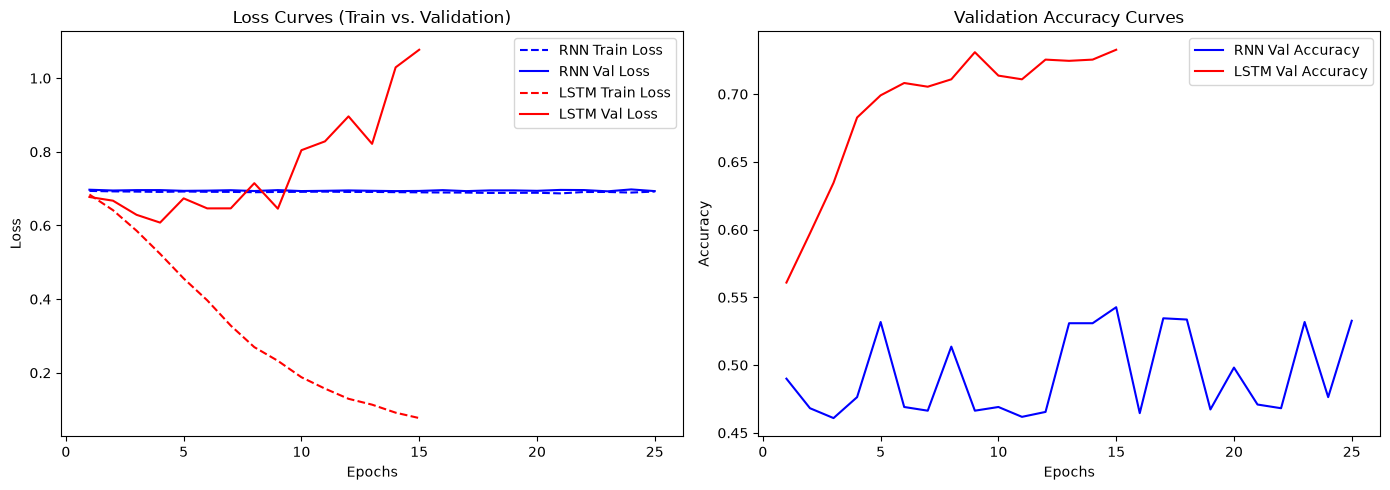

In [28]:
rnn_epochs = range(1, len(rnn_hist["train_loss"]) + 1)
lstm_epochs = range(1, len(lstm_hist["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss Curves
ax1.plot(rnn_epochs, rnn_hist['train_loss'], 'b--', label='RNN Train Loss')
ax1.plot(rnn_epochs, rnn_hist['val_loss'], 'b-', label='RNN Val Loss')
ax1.plot(lstm_epochs, lstm_hist['train_loss'], 'r--', label='LSTM Train Loss')
ax1.plot(lstm_epochs, lstm_hist['val_loss'], 'r-', label='LSTM Val Loss')
ax1.set_title('Loss Curves (Train vs. Validation)')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

# Plot 2: Accuracy Curves
ax2.plot(rnn_epochs, rnn_hist['val_acc'], 'b-', label='RNN Val Accuracy')
ax2.plot(lstm_epochs, lstm_hist['val_acc'], 'r-', label='LSTM Val Accuracy')
ax2.set_title('Validation Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()